# Emulating a Climate Model

Run it top to bottom. Every figure is produced here and saved in `images/`.

**Data (real model output):** ClimateBench v1.0 (Watson-Parris et al. 2022): emissions and annual
surface-air-temperature maps from the NorESM2-LM Earth system model (CMIP6), for 7 scenarios.

## Setup

In [1]:
# Python ≥3.8 is required
import sys
assert sys.version_info >= (3, 8)

# Scikit-Learn ≥1.0 is required
import sklearn
assert sklearn.__version__ >= "1.0"

# Common imports
import os
import time
import numpy as np
import pandas as pd

# To make this notebook's output stable across runs
np.random.seed(42)

# To plot pretty figures
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=13)
mpl.rc('xtick', labelsize=11)
mpl.rc('ytick', labelsize=11)

# Where to save the figures and the data
PROJECT_ROOT_DIR = "."
IMAGES_PATH = os.path.join(PROJECT_ROOT_DIR, "images")
DATA_PATH = os.path.join(PROJECT_ROOT_DIR, "datasets", "climatebench")
os.makedirs(IMAGES_PATH, exist_ok=True)
os.makedirs(DATA_PATH, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=150):
    path = os.path.join(IMAGES_PATH, fig_id + "." + fig_extension)
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

In [2]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

## Get the Data

In [3]:
import urllib.request
import tarfile

ZENODO = "https://zenodo.org/api/records/7064308/files/{}/content"
SCENARIOS = ["historical", "hist-GHG", "hist-aer", "ssp126", "ssp245", "ssp370", "ssp585"]
REDUCED = os.path.join(DATA_PATH, "climatebench_reduced.npz")

def reduce_climatebench(src, out=REDUCED):
    """Reads the original netCDF files and keeps what this project needs: global CO2 and CH4, the SO2 and
    black-carbon emission maps (coarsened 4x4), and the ensemble-mean temperature maps (coarsened 2x2)."""
    import xarray as xr
    D = {}
    for s in SCENARIOS:
        i = xr.open_dataset(os.path.join(src, f"inputs_{s}.nc"))
        o = xr.open_dataset(os.path.join(src, f"outputs_{s}.nc"))
        tas = o.tas.mean("member") if "member" in o.tas.dims else o.tas
        D[f"{s}/year"] = o.time.values.astype(int)
        D[f"{s}/members"] = np.array(o.sizes.get("member", 1))
        D[f"{s}/CO2"] = i.CO2.values.astype("f4")
        D[f"{s}/CH4"] = i.CH4.values.astype("f4")
        for v in ("SO2", "BC"):          # kg m-2 s-1, scaled by 1e11 to fit in float16
            D[f"{s}/{v}"] = (i[v].coarsen(latitude=4, longitude=4).mean().values * 1e11).astype("f2")
        D[f"{s}/tas"] = tas.coarsen(lat=2, lon=2).mean().values.astype("f2")
        if s == "ssp245":
            D[f"{s}/tas_members"] = o.tas.coarsen(lat=2, lon=2).mean().values.astype("f2")
    c = o.tas.coarsen(lat=2, lon=2).mean()
    D["lat"], D["lon"] = c.lat.values.astype("f4"), c.lon.values.astype("f4")
    pc = xr.open_dataset(os.path.join(src, "outputs_piControl.nc")).tas.coarsen(lat=2, lon=2).mean()
    D["piControl/tas"] = (pc - pc.mean("time")).values.astype("f2")
    np.savez_compressed(out, **D)

def fetch_climatebench():
    if not os.path.exists(REDUCED):       # about 900 MB to download, done only once
        raw = os.path.join(DATA_PATH, "raw")
        os.makedirs(raw, exist_ok=True)
        for f in ("train_val.tar.gz", "test.tar.gz"):
            path = os.path.join(raw, f)
            urllib.request.urlretrieve(ZENODO.format(f), path)
            with tarfile.open(path) as t:
                t.extractall(raw)
        reduce_climatebench(raw)
    return dict(np.load(REDUCED))

D = fetch_climatebench()
LAT, LON = D["lat"], D["lon"]
pd.DataFrame({s: dict(first_year=D[f"{s}/year"][0], last_year=D[f"{s}/year"][-1], years=len(D[f"{s}/year"]),
                      members=int(D[f"{s}/members"])) for s in SCENARIOS}).T

,first_year,last_year,years,members
historical,1850,2014,165,3
hist-GHG,1850,2014,165,3
hist-aer,1850,2014,165,3
ssp126,2015,2100,86,1
ssp245,2015,2100,86,3
ssp370,2015,2100,86,3
ssp585,2015,2100,86,1


In [4]:
print("CO2:", D["ssp245/CO2"].shape, " SO2:", D["ssp245/SO2"].shape, " tas:", D["ssp245/tas"].shape)

CO2: (86,)  SO2: (86, 24, 36)  tas: (86, 48, 72)


In [5]:
# Grid cells shrink towards the poles: weight every cell by cos(latitude)
WEIGHTS = np.repeat(np.cos(np.deg2rad(LAT))[:, None], len(LON), axis=1)
WEIGHTS = (WEIGHTS / WEIGHTS.mean()).ravel()

def global_mean(maps):
    maps = np.asarray(maps, dtype=float)
    return (maps.reshape(len(maps), -1) * WEIGHTS).mean(axis=1)

## Discover and Visualize the Data

Saving figure global_warming_plot


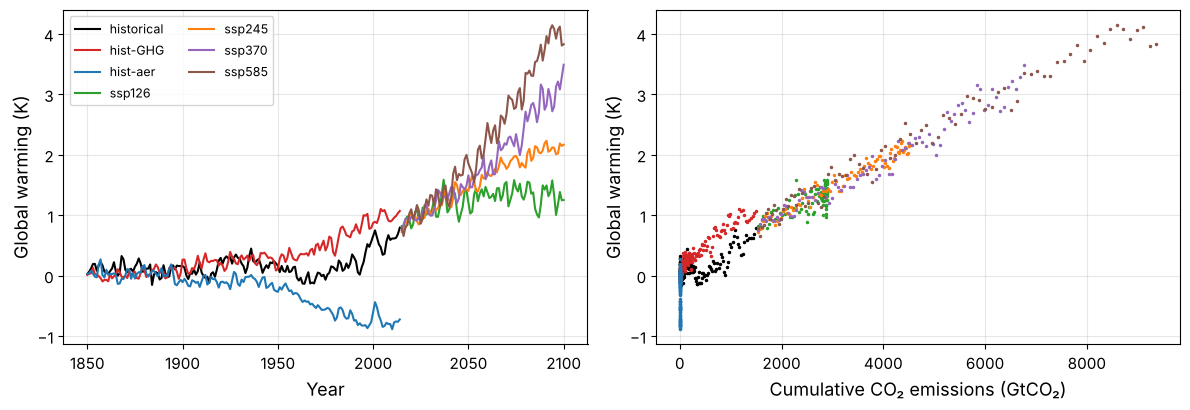

In [6]:
COLORS = {"historical": "k", "hist-GHG": "C3", "hist-aer": "C0", "ssp126": "C2", "ssp245": "C1",
          "ssp370": "C4", "ssp585": "C5"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for s in SCENARIOS:
    gm = global_mean(D[f"{s}/tas"])
    axes[0].plot(D[f"{s}/year"], gm, color=COLORS[s], label=s, lw=1.5)
    axes[1].plot(D[f"{s}/CO2"], gm, ".", color=COLORS[s], ms=3)
axes[0].set_xlabel("Year"); axes[0].set_ylabel("Global warming (K)")
axes[0].legend(fontsize=9, ncol=2)
axes[1].set_xlabel("Cumulative CO₂ emissions (GtCO₂)"); axes[1].set_ylabel("Global warming (K)")
for ax in axes:
    ax.grid(True, alpha=0.3)
save_fig("global_warming_plot")
plt.show()

In [7]:
from sklearn.linear_model import LinearRegression
ssp = [s for s in SCENARIOS if s.startswith("ssp") and s != "ssp245"]
co2_ssp = np.concatenate([D[f"{s}/CO2"] for s in ssp])
T_ssp = np.concatenate([global_mean(D[f"{s}/tas"]) for s in ssp])
tcre = LinearRegression().fit(co2_ssp[:, None] / 1000, T_ssp)
print(f"Warming per 1000 GtCO2 (TCRE) in NorESM2, from the training SSPs: {tcre.coef_[0]:.2f} K")

Warming per 1000 GtCO2 (TCRE) in NorESM2, from the training SSPs: 0.45 K


In [8]:
import matplotlib.colors as mcolors

def plot_map(ax, field, title, vmax=None, cmap="RdBu_r", label="K"):
    field = np.asarray(field, dtype=float).reshape(len(LAT), len(LON))
    vmax = vmax or np.nanmax(np.abs(field))
    lon = np.r_[LON, LON[0] + 360]                 # close the circle
    im = ax.pcolormesh(lon - 180, LAT, np.roll(np.c_[field, field[:, :1]], len(LON) // 2, axis=1),
                       cmap=cmap, norm=mcolors.TwoSlopeNorm(0, -vmax, vmax), shading="nearest")
    ax.set_title(title, fontsize=11)
    ax.set_xticks([-120, -60, 0, 60, 120], ["120°W", "60°W", "0°", "60°E", "120°E"], fontsize=8)
    ax.set_yticks([-60, 0, 60], ["60°S", "0°", "60°N"], fontsize=8)
    plt.colorbar(im, ax=ax, shrink=0.8, label=label)

Saving figure warming_maps_plot


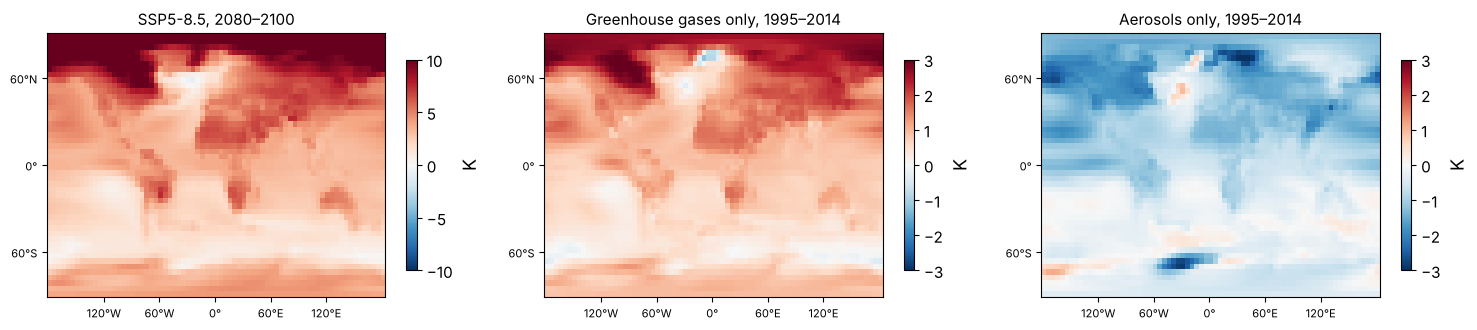

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
last20 = slice(-21, None)
plot_map(axes[0], D["ssp585/tas"][last20].astype(float).mean(0), "SSP5-8.5, 2080–2100", vmax=10)
plot_map(axes[1], D["hist-GHG/tas"][-20:].astype(float).mean(0), "Greenhouse gases only, 1995–2014", vmax=3)
plot_map(axes[2], D["hist-aer/tas"][-20:].astype(float).mean(0), "Aerosols only, 1995–2014", vmax=3)
save_fig("warming_maps_plot")
plt.show()

Saving figure so2_maps_plot


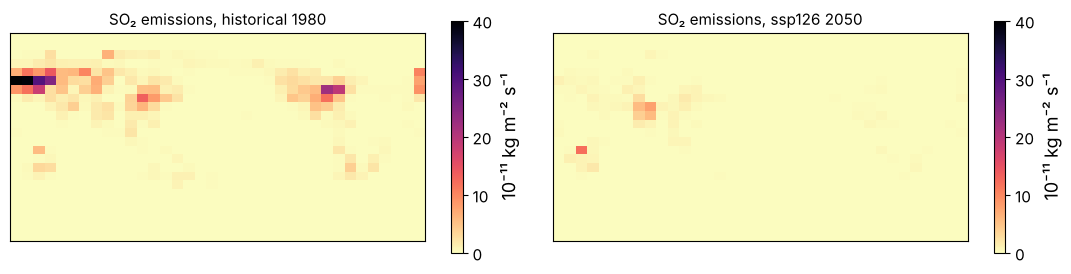

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, (s, yr) in zip(axes, (("historical", 1980), ("ssp126", 2050))):
    k = list(D[f"{s}/year"]).index(yr)
    m = D[f"{s}/SO2"][k].astype(float)
    im = ax.imshow(m, origin="lower", cmap="magma_r", extent=[-180, 180, -90, 90], vmax=40)
    ax.set_title(f"SO₂ emissions, {s} {yr}", fontsize=11); ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(im, ax=ax, shrink=0.8, label="10⁻¹¹ kg m⁻² s⁻¹")
save_fig("so2_maps_plot")
plt.show()

In [11]:
members = D["ssp245/tas_members"].astype(float).reshape(3, 86, -1)
ens_mean = D["ssp245/tas"].astype(float).reshape(86, -1)
def spatial_rmse(pred, truth, years=slice(None)):
    return np.sqrt(np.mean(((pred - truth)[years]) ** 2 * WEIGHTS))
def global_rmse(pred, truth, years=slice(None)):
    return np.sqrt(np.mean((global_mean(pred[years]) - global_mean(truth[years])) ** 2))
LAST = slice(-21, None)     # 2080-2100, the ClimateBench evaluation period
# How far is one realization from another? (members are independent draws of the internal variability)
pair = [spatial_rmse(members[i], members[j], LAST) for i in range(3) for j in range(i + 1, 3)]
pair_g = [global_rmse(members[i], members[j], LAST) for i in range(3) for j in range(i + 1, 3)]
# The 3-member mean still contains noise of std sigma/sqrt(3); between two members it is sigma*sqrt(2)
print(f"Member vs member, 2080-2100: spatial RMSE {np.mean(pair):.2f} K, global {np.mean(pair_g):.3f} K")
print(f"=> irreducible noise of the 3-member mean: spatial ~{np.mean(pair) / np.sqrt(6):.2f} K, "
      f"global ~{np.mean(pair_g) / np.sqrt(6):.3f} K")
pic = D["piControl/tas"].astype(float).reshape(-1, len(LAT) * len(LON))
print(f"piControl (no forcing): year-to-year std of global temperature {global_mean(pic).std():.3f} K")

Member vs member, 2080-2100: spatial RMSE 0.79 K, global 0.188 K
=> irreducible noise of the 3-member mean: spatial ~0.32 K, global ~0.077 K
piControl (no forcing): year-to-year std of global temperature 0.135 K


## Prepare the Data

In [12]:
TRAIN = ["historical", "hist-GHG", "hist-aer", "ssp126", "ssp370", "ssp585"]
TEST = "ssp245"

def stack(names, key):
    return np.concatenate([D[f"{s}/{key}"].astype(float).reshape(len(D[f"{s}/year"]), -1) for s in names])

Y_train = stack(TRAIN, "tas")
Y_test = stack([TEST], "tas")
groups = np.concatenate([[s] * len(D[f"{s}/year"]) for s in TRAIN])
print("training years:", len(Y_train), " test years:", len(Y_test), " outputs per year:", Y_train.shape[1])

training years: 753  test years: 86  outputs per year: 3456


In [13]:
from sklearn.decomposition import PCA

so2_pca = PCA(n_components=5).fit(stack(TRAIN, "SO2"))
bc_pca = PCA(n_components=5).fit(stack(TRAIN, "BC"))
print("SO2 EOFs, explained variance:", so2_pca.explained_variance_ratio_.round(3))
print("BC  EOFs, explained variance:", bc_pca.explained_variance_ratio_.round(3))

def make_inputs(names):
    return np.c_[np.concatenate([D[f"{s}/CO2"] for s in names]) / 1000,     # TtCO2
                 np.concatenate([D[f"{s}/CH4"] for s in names]),
                 so2_pca.transform(stack(names, "SO2")) / 100,
                 bc_pca.transform(stack(names, "BC")) / 10]
INPUTS = ["CO2_cum", "CH4"] + [f"SO2_{i}" for i in range(5)] + [f"BC_{i}" for i in range(5)]
X_train, X_test = make_inputs(TRAIN), make_inputs([TEST])
pd.DataFrame(X_train, columns=INPUTS).describe().round(2).T[["mean", "std", "min", "max"]]

SO2 EOFs, explained variance: [0.525 0.369 0.049 0.026 0.008]
BC  EOFs, explained variance: [0.837 0.107 0.032 0.011 0.004]


,mean,std,min,max
CO2_cum,1.40,2.00,0.00,9.36
CH4,0.21,0.21,0.00,0.75
SO2_0,0.00,0.23,-0.19,0.72
SO2_1,-0.00,0.20,-0.20,0.48
SO2_2,0.00,0.07,-0.23,0.19
SO2_3,-0.00,0.05,-0.13,0.17
SO2_4,0.00,0.03,-0.13,0.07
BC_0,0.00,0.16,-0.15,0.39
BC_1,0.00,0.06,-0.07,0.12
BC_2,0.00,0.03,-0.06,0.09


Saving figure eof_plot


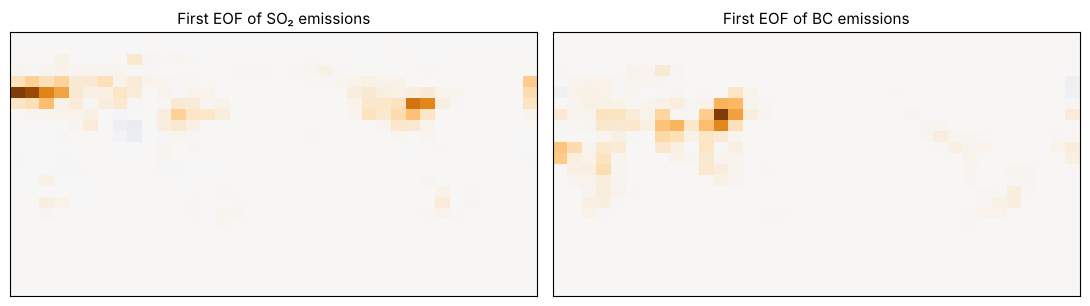

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, (pca, name) in zip(axes, ((so2_pca, "SO₂"), (bc_pca, "BC"))):
    eof = pca.components_[0].reshape(D["ssp245/SO2"].shape[1:])
    v = np.abs(eof).max()
    im = ax.imshow(eof, origin="lower", cmap="PuOr_r", vmin=-v, vmax=v, extent=[-180, 180, -90, 90])
    ax.set_title(f"First EOF of {name} emissions", fontsize=11); ax.set_xticks([]); ax.set_yticks([])
save_fig("eof_plot")
plt.show()

## Select and Train a Model

In [15]:
from sklearn.base import BaseEstimator, RegressorMixin

class PatternScaling(BaseEstimator, RegressorMixin):
    """The classic emulator: predict the global-mean warming with a linear model,
    then multiply by a fixed spatial pattern (one slope per grid cell)."""
    def fit(self, X, Y):
        g = global_mean(Y)
        self.global_ = LinearRegression().fit(X, g)
        self.pattern_ = np.linalg.lstsq(g[:, None], Y, rcond=None)[0]
        return self
    def predict(self, X):
        return self.global_.predict(X)[:, None] * self.pattern_

ps = PatternScaling().fit(X_train, Y_train)
print(f"Pattern scaling, training spatial RMSE: {spatial_rmse(ps.predict(X_train), Y_train):.3f} K")

Pattern scaling, training spatial RMSE: 0.477 K


In [16]:
n, p, m = len(X_train), X_train.shape[1] + 2, Y_train.shape[1]
print(f"Scikit-Learn's GP gradient for {m} outputs would need an {n} x {n} x {p} x {m} array: "
      f"{n * n * p * m * 8 / 1e9:,.0f} GB")

Scikit-Learn's GP gradient for 3456 outputs would need an 753 x 753 x 14 x 3456 array: 219 GB


In [17]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, ConstantKernel as C, WhiteKernel
from sklearn.preprocessing import StandardScaler

class SharedKernelGP(BaseEstimator, RegressorMixin):
    """A GP emulator of temperature maps.
    1. Learn the kernel's hyperparameters on the global mean (one output: cheap and well defined).
    2. Compress the maps with PCA (n_pcs patterns) and reuse that kernel for all PCA scores at once,
       with the noise level of a single grid cell (internal variability of an ensemble mean)."""
    def __init__(self, nu=2.5, n_restarts=2, n_pcs=20, cell_noise=0.0):
        self.nu, self.n_restarts, self.n_pcs, self.cell_noise = nu, n_restarts, n_pcs, cell_noise
    def _kernel(self, d):
        base = RBF(np.ones(d), (1e-2, 1e3)) if self.nu == np.inf else Matern(np.ones(d), (1e-2, 1e3), nu=self.nu)
        return C(1.0) * base + WhiteKernel(1e-2, (1e-6, 1.0))
    def fit(self, X, Y):
        self.scaler_ = StandardScaler().fit(X)
        Xs = self.scaler_.transform(X)
        g = global_mean(Y)
        self.global_gp_ = GaussianProcessRegressor(self._kernel(X.shape[1]), normalize_y=True,
                                                   n_restarts_optimizer=self.n_restarts, random_state=42).fit(Xs, g)
        self.y_std_ = g.std()
        k = self.global_gp_.kernel_
        map_kernel = k.k1 + WhiteKernel(k.k2.noise_level + self.cell_noise / self.y_std_ ** 2, "fixed")
        self.pca_ = PCA(n_components=self.n_pcs).fit(Y)
        self.map_gp_ = GaussianProcessRegressor(map_kernel, optimizer=None).fit(Xs, self.pca_.transform(Y) / self.y_std_)
        return self
    def predict(self, X, return_std=False):
        Xs = self.scaler_.transform(X)
        P = self.pca_.inverse_transform(self.map_gp_.predict(Xs) * self.y_std_)
        if return_std:
            return P, self.global_gp_.predict(Xs, return_std=True)
        return P

# Noise of one grid cell in the training targets: piControl variance / number of ensemble members, averaged
members_per_year = np.concatenate([[int(D[f"{s}/members"])] * len(D[f"{s}/year"]) for s in TRAIN])
CELL_NOISE = pic.var(axis=0).mean() * np.mean(1 / members_per_year)
print(f"internal-variability variance of one grid cell in the training targets: {CELL_NOISE:.3f} K²")

t0 = time.time()
gp = SharedKernelGP(cell_noise=CELL_NOISE).fit(X_train, Y_train)
print(f"fitted in {time.time() - t0:.0f} s:", gp.global_gp_.kernel_)

internal-variability variance of one grid cell in the training targets: 0.236 K²


fitted in 110 s: 1.48**2 * Matern(length_scale=[0.875, 8.45, 30.6, 13.7, 1e+03, 1e+03, 573, 1e+03, 1e+03, 21.2, 11.6, 73], nu=2.5) + WhiteKernel(noise_level=0.0115)


In [18]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor

models = {
    "Pattern scaling": PatternScaling(),
    "Ridge regression": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Random forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=42, n_jobs=-1),
    "Neural network (MLP)": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 64), alpha=1e-2,
                                          max_iter=3000, early_stopping=True, random_state=42)),
    "Gaussian process (PCA + shared kernel)": SharedKernelGP(n_restarts=0, cell_noise=CELL_NOISE),
}

In [19]:
# Leave-one-scenario-out cross-validation: each fold hides a whole scenario
from sklearn.model_selection import LeaveOneGroupOut

def loso_scores(model):
    rows = {}
    for tr, va in LeaveOneGroupOut().split(X_train, Y_train, groups):
        s = groups[va][0]
        P = sklearn.base.clone(model).fit(X_train[tr], Y_train[tr]).predict(X_train[va])
        rows[s] = global_rmse(P, Y_train[va])
    return rows

t0 = time.time()
loso = pd.DataFrame({name: loso_scores(model) for name, model in models.items()}).T
loso["mean"] = loso.mean(axis=1)
print(f"({time.time() - t0:.0f} s)")
loso.round(3).sort_values("mean")

(148 s)


,hist-GHG,hist-aer,historical,ssp126,ssp370,ssp585,mean
Ridge regression,0.202,0.176,0.169,0.163,0.415,0.366,0.249
Pattern scaling,0.176,0.167,0.169,0.154,0.389,0.482,0.256
Gaussian process (PCA + shared kernel),0.104,0.245,0.132,0.184,0.167,1.024,0.309
Random forest,0.252,0.434,0.236,0.334,0.481,0.888,0.438
Neural network (MLP),0.334,0.504,0.410,0.224,0.748,0.671,0.482


## Fine-Tune Your Model

In [20]:
rows = []
for nu, name in ((0.5, "Matérn 1/2"), (1.5, "Matérn 3/2"), (2.5, "Matérn 5/2"), (np.inf, "RBF")):
    sc = loso_scores(SharedKernelGP(nu=nu, n_restarts=0, cell_noise=CELL_NOISE))
    rows.append(dict(kernel=name, **sc, mean=np.mean(list(sc.values()))))
kernel_cv = pd.DataFrame(rows).set_index("kernel")
kernel_cv.round(3)

,hist-GHG,hist-aer,historical,ssp126,ssp370,ssp585,mean
kernel,,,,,,,
Matérn 1/2,0.218,0.409,0.181,0.195,0.166,0.654,0.304
Matérn 3/2,0.108,0.312,0.131,0.150,0.162,0.728,0.265
Matérn 5/2,0.104,0.245,0.132,0.184,0.167,1.024,0.309
RBF,0.121,0.248,0.141,0.153,0.181,0.527,0.228


In [21]:
NU = {"Matérn 1/2": 0.5, "Matérn 3/2": 1.5, "Matérn 5/2": 2.5, "RBF": np.inf}[kernel_cv["mean"].idxmin()]
gp = SharedKernelGP(nu=NU, cell_noise=CELL_NOISE).fit(X_train, Y_train)
print("best kernel by leave-one-scenario-out CV:", kernel_cv["mean"].idxmin())
print(gp.global_gp_.kernel_)
print(f"20 PCA patterns explain {gp.pca_.explained_variance_ratio_.sum():.1%} of the variance of the maps")

best kernel by leave-one-scenario-out CV: RBF
1.75**2 * RBF(length_scale=[1.33, 3.89, 1e+03, 12.4, 1e+03, 1e+03, 191, 1e+03, 14.8, 1e+03, 5.25, 154]) + WhiteKernel(noise_level=0.0127)
20 PCA patterns explain 96.8% of the variance of the maps


In [22]:
k = gp.global_gp_.kernel_
pd.Series(1 / k.k1.k2.length_scale, index=INPUTS, name="1 / length scale").round(3).sort_values(ascending=False)

CO2_cum    0.749
CH4        0.257
BC_3       0.191
SO2_1      0.081
BC_1       0.068
BC_4       0.006
SO2_4      0.005
SO2_0      0.001
BC_0       0.001
SO2_3      0.001
SO2_2      0.001
BC_2       0.001
Name: 1 / length scale, dtype: float64

## Evaluate on the Test Scenario (SSP2-4.5)

In [23]:
rows = {}
preds = {}
for name, model in models.items():
    final = gp if name.startswith("Gaussian") else sklearn.base.clone(model).fit(X_train, Y_train)
    preds[name] = final.predict(X_test)
    rows[name] = dict(spatial_2080_2100=spatial_rmse(preds[name], Y_test, LAST),
                      global_2080_2100=global_rmse(preds[name], Y_test, LAST),
                      spatial_all_years=spatial_rmse(preds[name], Y_test))
rows["(noise floor of the target)"] = dict(spatial_2080_2100=np.mean(pair) / np.sqrt(6),
                                           global_2080_2100=np.mean(pair_g) / np.sqrt(6), spatial_all_years=np.nan)
pd.DataFrame(rows).T.round(3)

,spatial_2080_2100,global_2080_2100,spatial_all_years
Pattern scaling,0.372,0.125,0.444
Ridge regression,0.388,0.106,0.414
Random forest,0.690,0.519,0.544
Neural network (MLP),0.391,0.184,0.413
Gaussian process (PCA + shared kernel),0.378,0.154,0.368
(noise floor of the target),0.321,0.077,NaN


Saving figure test_global_plot


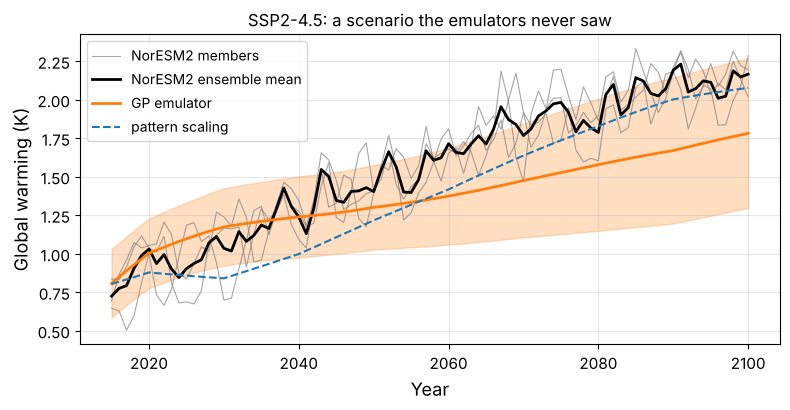

GP 95% band covers the ensemble mean in 77% of the years


In [24]:
P_gp, (g_mu, g_sd) = gp.predict(X_test, return_std=True)
years = D["ssp245/year"]
fig, ax = plt.subplots(figsize=(8, 4.2))
for k_ in range(3):
    ax.plot(years, global_mean(members[k_]), color="gray", lw=0.8, alpha=0.7, label="NorESM2 members" if k_ == 0 else None)
ax.plot(years, global_mean(Y_test), "k", lw=2, label="NorESM2 ensemble mean")
ax.plot(years, g_mu, "C1", lw=2, label="GP emulator")
ax.fill_between(years, g_mu - 1.96 * g_sd, g_mu + 1.96 * g_sd, color="C1", alpha=0.25)
ax.plot(years, global_mean(preds["Pattern scaling"]), "C0--", lw=1.5, label="pattern scaling")
ax.set_xlabel("Year"); ax.set_ylabel("Global warming (K)")
ax.set_title("SSP2-4.5: a scenario the emulators never saw")
ax.legend()
ax.grid(True, alpha=0.3)
save_fig("test_global_plot")
plt.show()
print(f"GP 95% band covers the ensemble mean in {np.mean(np.abs(global_mean(Y_test) - g_mu) <= 1.96 * g_sd):.0%} of the years")

Saving figure test_maps_plot


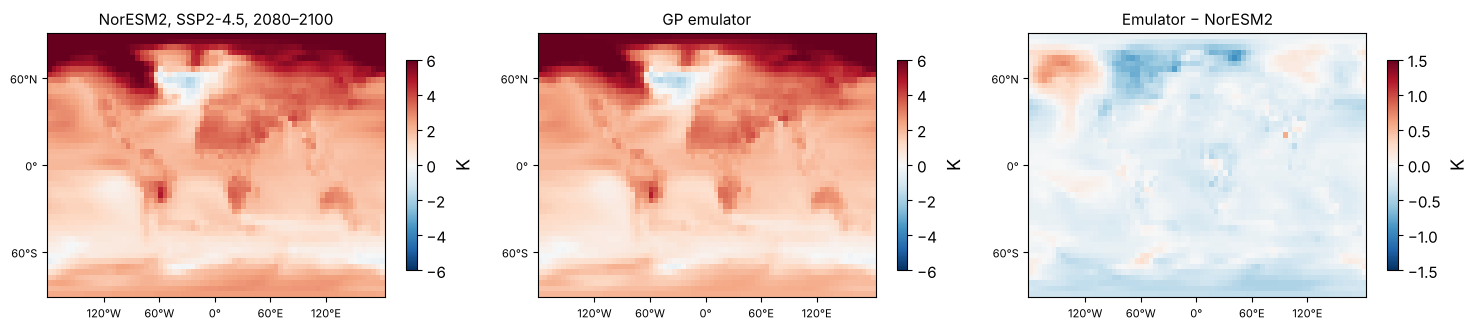

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
truth = Y_test[LAST].mean(0)
plot_map(axes[0], truth, "NorESM2, SSP2-4.5, 2080–2100", vmax=6)
plot_map(axes[1], P_gp[LAST].mean(0), "GP emulator", vmax=6)
plot_map(axes[2], P_gp[LAST].mean(0) - truth, "Emulator − NorESM2", vmax=1.5)
save_fig("test_maps_plot")
plt.show()

## Use the Emulator: Explore New Scenarios

In [26]:
t0 = time.time()
for _ in range(100):
    gp.predict(X_test)
emu_time = (time.time() - t0) / 100
print(f"Emulating 86 years of global temperature maps: {1e3 * emu_time:.0f} ms")

Emulating 86 years of global temperature maps: 2 ms


In [27]:
def build_scenario(netzero_year, aerosol="ssp245", start=2015):
    """A custom pathway: CO2 emissions follow SSP2-4.5 until 2020, then fall linearly to zero in
    `netzero_year`; CH4 and aerosols are borrowed from an existing scenario."""
    yrs = np.arange(start, 2101)
    cum = D["ssp245/CO2"].astype(float)
    annual = np.diff(np.r_[D["historical/CO2"][-1], cum])                 # GtCO2 per year
    e2020 = annual[yrs == 2020][0]
    emis = np.where(yrs <= 2020, annual, np.clip(e2020 * (netzero_year - yrs) / (netzero_year - 2020), 0, None))
    co2_cum = D["historical/CO2"][-1] + np.cumsum(emis)
    X = make_inputs([aerosol])
    X[:, 0] = co2_cum / 1000
    return yrs, X

rows = []
for nz in (2040, 2050, 2060, 2070, 2080, 2100):
    yrs, Xs_ = build_scenario(nz)
    P, (mu_, sd_) = gp.predict(Xs_, return_std=True)
    rows.append(dict(net_zero=nz, cumulative_2100=Xs_[-1, 0] * 1000, peak_warming=mu_.max(),
                     warming_2100=mu_[-1], uncertainty_95=1.96 * sd_[-1]))
scen = pd.DataFrame(rows).set_index("net_zero")
scen.round(2)

,cumulative_2100,peak_warming,warming_2100,uncertainty_95
net_zero,,,,
2040,2074.63,1.20,1.20,0.23
2050,2261.55,1.25,1.25,0.23
2060,2448.46,1.29,1.29,0.23
2070,2635.38,1.33,1.33,0.23
2080,2822.29,1.36,1.36,0.24
2100,3196.12,1.44,1.44,0.26


Saving figure carbon_budget_plot


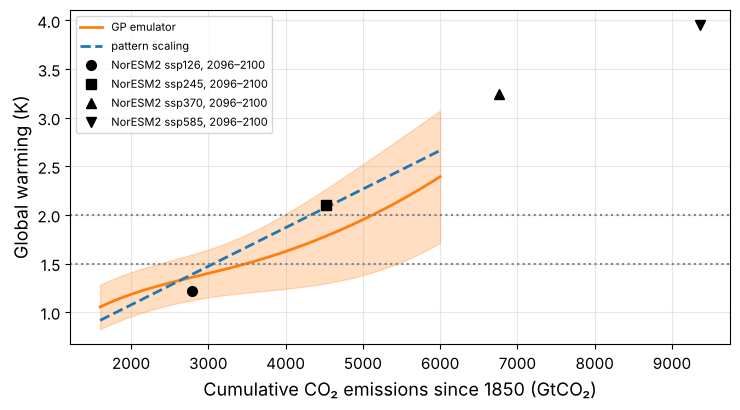

1.5 K, GP             : 3,502 GtCO2 in total, 2,001 GtCO2 after 2014
1.5 K, pattern scaling: 3,081 GtCO2 in total, 1,581 GtCO2 after 2014
2.0 K, GP             : 5,138 GtCO2 in total, 3,637 GtCO2 after 2014
2.0 K, pattern scaling: 4,342 GtCO2 in total, 2,841 GtCO2 after 2014


In [28]:
cum = np.linspace(1600, 6000, 200)
yrs, X0 = build_scenario(2050)
Xb = np.repeat(X0[-1:], len(cum), axis=0)          # aerosols and CH4 of 2100, cumulative CO2 varies
Xb[:, 0] = cum / 1000
_, (mu_b, sd_b) = gp.predict(Xb, return_std=True)
lin_b = global_mean(ps.predict(Xb))                  # pattern scaling: linear in cumulative CO2
plt.figure(figsize=(7.5, 4.2))
plt.plot(cum, mu_b, "C1", lw=2, label="GP emulator")
plt.fill_between(cum, mu_b - 1.96 * sd_b, mu_b + 1.96 * sd_b, color="C1", alpha=0.25)
plt.plot(cum, lin_b, "C0--", lw=2, label="pattern scaling")
for s, mk in (("ssp126", "o"), ("ssp245", "s"), ("ssp370", "^"), ("ssp585", "v")):
    plt.plot(D[f"{s}/CO2"][-1], global_mean(D[f"{s}/tas"][-5:]).mean(), "k" + mk, ms=7, label=f"NorESM2 {s}, 2096–2100")
for lim in (1.5, 2.0):
    plt.axhline(lim, color="gray", ls=":")
plt.xlabel("Cumulative CO₂ emissions since 1850 (GtCO₂)"); plt.ylabel("Global warming (K)")
plt.legend(loc="upper left", fontsize=8)
plt.grid(True, alpha=0.3)
save_fig("carbon_budget_plot")
plt.show()
so_far = D["historical/CO2"][-1]
for lim in (1.5, 2.0):
    for name, curve in (("GP", mu_b), ("pattern scaling", lin_b)):
        c_ = cum[np.argmax(curve >= lim)] if (curve >= lim).any() else np.nan
        print(f"{lim} K, {name:15s}: {c_:,.0f} GtCO2 in total, {c_ - so_far:,.0f} GtCO2 after 2014")

## Launch, Monitor, and Maintain

In [29]:
import joblib
joblib.dump(dict(model=gp, so2_pca=so2_pca, bc_pca=bc_pca, inputs=INPUTS), "climate_emulator.pkl")
print("saved;", os.path.getsize("climate_emulator.pkl") // 1_000_000, "MB")

saved; 10 MB


In [30]:
import json
os.makedirs("animations", exist_ok=True)
Xs_tr = gp.scaler_.transform(X_train)
kg = gp.global_gp_
anim = dict(
    X=Xs_tr.round(6).tolist(), alphaZ=gp.map_gp_.alpha_.round(6).tolist(),
    pcs=gp.pca_.components_.round(5).tolist(), map_mean=gp.pca_.mean_.round(4).tolist(), y_std=float(gp.y_std_),
    g_alpha=kg.alpha_.ravel().tolist(), g_mean=float(kg._y_train_mean), g_std=float(kg._y_train_std),
    amp=float(kg.kernel_.k1.k1.constant_value), ell=kg.kernel_.k1.k2.length_scale.tolist(),
    nu=float(getattr(kg.kernel_.k1.k2, "nu", -1)), band95=float(scen.uncertainty_95.mean()),
    sc_mean=gp.scaler_.mean_.tolist(), sc_scale=gp.scaler_.scale_.tolist(),
    co2_hist_2014=float(D["historical/CO2"][-1]),
    co2_ssp245=D["ssp245/CO2"].astype(float).round(2).tolist(),
    aer={s: make_inputs([s])[:, 1:].round(5).tolist() for s in ("ssp126", "ssp245", "ssp370")},
    truth245=global_mean(Y_test).round(3).tolist(), lat=LAT.tolist(), nlon=len(LON),
    check_g=gp.predict(X_test, return_std=True)[1][0].round(4).tolist(), check_map=gp.predict(X_test)[-1].round(4).tolist())
with open(os.path.join("animations", "data.json"), "w") as f:
    json.dump(anim, f, separators=(",", ":"))
print("exported", os.path.getsize(os.path.join("animations", "data.json")) // 1024, "KB")

exported 883 KB
